In [1]:
from sage.all import *
from sage.interfaces.gap import gap
from sage.groups.perm_gps.permgroup import direct_product_permgroups
from sage.groups.free_group import FreeGroup
import matplotlib.pyplot as plt
import itertools
import random

Now, we using a gap group, we construct a cayley graph. The generating set is user specified, but if it is not given, then we use the minimal generating set from GAP. We will be using the convention that $\gamma \in G$ denotes an element of the group, and $s \in S$ is an element of the generating set.

In [2]:
def is_abelian_gens(gens):
    return all(a * b == b * a for a, b in itertools.combinations(gens, 2))

In [5]:
#here G must be a gap object. The runtime of this is |G| |S| + the time it takes to list the elements of the group. 
def cayley_graph_data_from_group(G, gens = None, group_name=None):
    if gens is None:
        gens = list(gap.MinimalGeneratingSet(G))
    elems = list(gap.Elements(G))
    elem_to_idx = {gamma: i for i, gamma in enumerate(elems)}
    edge_index = [] #the length of this is |G| |S| (the number of directed edges)
    edge_label = [] #label of the edge i.e. the generator used. this is important!
    for gamma_idx, gamma in enumerate(elems):
        for s in gens:
            gamma_next = gamma * s
            edge_index.append([gamma_idx, elem_to_idx[gamma_next]])
            edge_label.append(elem_to_idx[s])
    #So will return edge_index as [[x_1, s_1 x_1], [x_1, s_2 x_1],...,[x]]. So these edges are directed edges. 
    #this is a dictionary.
    data = {
        "edge_index": edge_index,
        "edge_label": edge_label,
        "num_generators" : len(gens),
        "num_vertices" : len(elems),
        "num_edges" : len(edge_label),
        "is_abelian": int(is_abelian_gens(gens)),
        "group_id": str(gap.StructureDescription(G))
    }
    return data


In [4]:
#gives "num_groups" groups of order "order" with randomly chosen generating sets.
def small_groups_order_n(order, num_groups=1, generating_sets_per_group=1):
    result = []
    for i in range(1, num_groups + 1):
        G = gap.SmallGroup(order, i)
        canonical_gen_set = tuple(gap.MinimalGeneratingSet(G))
        seen_gens = {canonical_gen_set}
        result.append([G, list(canonical_gen_set)])
        count = 1
        identity = gap.Identity(G)
        elems = list(gap.Elements(G))
        elems_no_id = [e for e in elems if e != identity]
        exhausted = False
        attempts = 0
        max_attempts = generating_sets_per_group * 100
        while count < generating_sets_per_group and not exhausted:
            attempts += 1
            if attempts > max_attempts:
                exhausted = True
                break
            k = random.randint(1, min(5, len(elems_no_id)))
            gens = tuple(sorted(random.sample(elems_no_id, k)))
            if gens in seen_gens:
                continue
            seen_gens.add(gens)  # add regardless, to avoid rechecking
            if gap.Group(gens) == G:
                result.append([G, list(gens)])
                count += 1
    return result

In [9]:
small_groups_order_n(32,4,2)

[[Group( [ f1, f2, f3, f4, f5 ] ), [f1]],
 [Group( [ f1, f2, f3, f4, f5 ] ), [f2*f3, f4*f5, f1*f2*f3*f4]],
 [Group( [ f1, f2, f3, f4, f5 ] ), [f1, f2]],
 [Group( [ f1, f2, f3, f4, f5 ] ), [f2*f4, f3*f5, f2*f4*f5, f1*f3*f4*f5]],
 [Group( [ f1, f2, f3, f4, f5 ] ), [f1, f2]],
 [Group( [ f1, f2, f3, f4, f5 ] ), [f1*f4, f1*f2*f4]],
 [Group( [ f1, f2, f3, f4, f5 ] ), [f1, f2]],
 [Group( [ f1, f2, f3, f4, f5 ] ), [f1*f4, f2*f4*f5, f3*f4*f5, f1*f2*f3*f5]]]

In [11]:
import json

def save_cayley_dicts_jsonl(cayley_dicts, path):
    with open(path, "w") as f:
        for d in cayley_dicts:
            f.write(json.dumps(d) + "\n")
    

import itertools
#flattens at the first level. 
def flatten(lists):
    return list(itertools.chain.from_iterable(lists))

In [ ]:
small_groups_unique_100 = []
for order in range(1,101):
    num_groups = int(gap.NumberSmallGroups(order))
    groups = small_groups_order_n(order,num_groups,1)
    small_groups_unique_100.append(groups)
    
small_groups_unique_100 = flatten(small_groups_unique_100)
cayley_dict_unique_100 = [cayley_graph_data_from_group(group, gens) for [group, gens] in small_groups_unique_100]
save_cayley_dicts_jsonl(cayley_dict_unique_100, "../data/cayley_dict_unique_100.jsonl")

In [ ]:
small_groups_five_gens_each_50 = []
for order in range(2,51):
    num_groups = int(gap.NumberSmallGroups(order))
    groups = small_groups_order_n(order,num_groups,5)
    small_groups_five_gens_each_50.append(groups)

small_groups_five_gens_each_50 = flatten(small_groups_five_gens_each_50)
cayley_dict_five_gens_each_50 = [cayley_graph_data_from_group(group, gens) for [group, gens] in small_groups_five_gens_each_50]
save_cayley_dicts_jsonl(cayley_dict_five_gens_each_50, "../data/cayley_five_gens_each_50.jsonl")

In [13]:
small_groups_ten_gens_each_50 = []
for order in range(2,51):
    num_groups = int(gap.NumberSmallGroups(order))
    groups = small_groups_order_n(order,num_groups,10)
    small_groups_ten_gens_each_50.append(groups)

small_groups_ten_gens_each_50 = flatten(small_groups_ten_gens_each_50)
cayley_dict_ten_gens_each_50 = [cayley_graph_data_from_group(group, gens) for [group, gens] in small_groups_ten_gens_each_50]
save_cayley_dicts_jsonl(cayley_dict_ten_gens_each_50, "../data/cayley_ten_gens_each_50.jsonl")

IOStream.flush timed out
IOStream.flush timed out


In [14]:
small_groups_unique_51_200 = []
for order in range(51,201):
    num_groups = int(gap.NumberSmallGroups(order))
    groups = small_groups_order_n(order,num_groups, 1)
    small_groups_unique_51_200.append(groups)

small_groups_unique_51_200 = flatten(small_groups_unique_51_200)
cayley_dict_unique_51_200 = [cayley_graph_data_from_group(group, gens) for [group, gens] in small_groups_unique_51_200]
save_cayley_dicts_jsonl(cayley_dict_unique_51_200, "../data/cayley_dict_unique_51_200.jsonl")

In [15]:
small_groups_five_gens_each_51_150 = []
for order in range(51,151):
    num_groups = int(gap.NumberSmallGroups(order))
    groups = small_groups_order_n(order,num_groups, 5)
    small_groups_five_gens_each_51_150.append(groups)

small_groups_five_gens_each_51_150 = flatten(small_groups_five_gens_each_51_150)
cayley_dict_five_gens_each_51_150 = [cayley_graph_data_from_group(group, gens) for [group, gens] in small_groups_five_gens_each_51_150]
save_cayley_dicts_jsonl(cayley_dict_five_gens_each_51_150, "../data/cayley_dict_five_gens_each_51_150.jsonl")

In [45]:
small_groups_unique_151_250 = []
for order in range(151,250):
    num_groups = int(gap.NumberSmallGroups(order))
    groups = small_groups_order_n(order,num_groups,1)
    small_groups_unique_151_250.append(groups)
    
small_groups_unique_151_250 = flatten(small_groups_unique_151_250)

In [46]:

cayley_dict_unique_151_250 = [cayley_graph_data_from_group(group, gens) for [group, gens] in small_groups_unique_151_250]

In [47]:
save_cayley_dicts_jsonl(cayley_dict_unique_151_250, "../data/cayley_dict_unique_151_250.jsonl")

### **Formalising the problem**

Now, we generating training and test data sets. We have shown using that if, as labelled graphs, $\text{Cay}(G_1,S_1) \cong \text{Cay}(G_2,S_2)$, then there is an isomorphism $\phi : G_1 \rightarrow G_2$ where $\phi(S_1) = S_2$ (for connected cayley graphs - which are what we care about here). This means that a cayley graph determines the group up to isomorphism; more formally there is a functor $\phi : \mathcal{C} \rightarrow \textbf{Group}$ taking $\text{Cay}(G,S) \mapsto G$ from the category $\mathcal{C}$ of connected cayley graphs to the category of groups $\textbf{Group}$. Note that there is also a functor $\psi : \textbf{Group} \rightarrow \mathcal{C}$ taking $G \mapsto \textbf{Cay}(G,G)$ because $G$ is a generating set. Here we will now think of these categories as sets to avoid pedantic technical details which are not usful here.

If we have a function $F : \textbf{Group} \rightarrow Y$ which is something we want to learn using ML, then we can construct $H = F \circ \phi: \mathcal{C} \rightarrow Y$ and learn this composed function, ending up with a learned function $\tilde{H} \approx H$. Finally, the composition $H \circ \psi : \text{Group} \rightarrow Y$ will hopefully agree with $F$ on most groups!

If we want to learn the function $F(G) = 1$ if $G$ abelian and $0$ if not, then we notice that $F$ depends on $G$ up to isomorphism; in fact mathematicians only care about properties of objects up to isomorphism which are those that don't depend on their representation, which is usually in terms of sets. This is the reason category theory was invented! 

More rigorously, any function $F$ we care about will factor through $\textbf{Group} / \cong$ where $\cong$ is the isomorphism equivalence relation, and so we can instead learn $F : \textbf{Group} / \cong \rightarrow Y$. The map $\pi \circ \phi : \mathcal{C} \rightarrow \textbf{Group} / \cong$ factors through $ \mathcal{C} / \sim$ where $\text{Cay}(G_{1},S) \sim \text{Cay}(G_{2},S)$ if $G_{1} \cong G_{2}$, where $\sim$ is an equivalence relation on the set of cayley graphs. So we can instead learn $H : \mathcal{C}/ \sim \rightarrow Y$.

Note that if $\sigma : G_{2} \rightarrow G_{1}$ is an isomorphism, then $\text{Cay}(G_{2}, S_{2}) \cong \text{Cay}(G_{1}, \sigma(S_{2}))$. This means if 2 cayley graphs are equivalent under $\sim$, they must belong to the same group but can have different generating sets. So in fact our learned function $H$ should not only be invariant under automorphisms of a cayley graph, but also the choice of generating set. This is where the geometric deep learning aspect comes in!


### **Learning whether a group is abelian**

#### **Naive approach**

Here we use a standard GNN and do not try to enforce any equivariance/invariance. Let's create a quick dataset here. 

In [3]:
def generate_random_elements(G, k):
    #generate k distinct non-identity permutations from a group G
    identity = gap.Identity(G)
    elems = []
    while len(elems) < k:
        g = gap.Random(G)
        if g != identity and not(g in elems):
            elems.append(g)
    return elems

In [4]:
  #choose some random sample of permutations from symmetric group of N2. generate group by these. 
  #do this N_1 times to get N_1 groups.
  # rng = random.Random(seed)
  #runtime is O(N1 max_gens) (worst-case).
def make_random_groups(N_1, N_2, min_gens = 1, max_gens = 5, seed = 0):
    rng = random.Random(seed)
    groups = []
    num_groups = 0 
    Sn = gap.SymmetricGroup(N_2)
    #all_elems = list(gap.Elements(Sn))
    identity = gap.Identity(Sn)
    while num_groups < N_1:
      k = rng.randint(min_gens, max_gens)
      gens = generate_random_elements(Sn, k)
      G = [gap.Group(gens), gens]
      groups.append(G)
      num_groups += 1
      
    return groups

In [5]:
randomgroups = make_random_groups(1000, 10,1,7)
randomgroups

NameError: name 'random' is not defined

In [ ]:
def group_id_str(G):
    try:
        gid = list(gap.IdGroup(G).sage())
        return f"SmallGroup({gid[0]},{gid[1]})"
    except Exception:
        try:
            return str(gap.StructureDescription(G))
        except Exception:
            return str(G)


def safe_gap_group_name(G):
    try:
        return group_id_str(G)
    except Exception:
        return "unknown"

#### **Enforcing invariance**

### **Encoder**

# **Some other functions**

In [ ]:
def random_generating_set_for_group(
    G,
    min_gens=1,
    max_gens=4,
    rng=None,
    max_tries=200,
):
    """
    Return a random generating set for the given GAP group G.

    We sample random subsets of elements of G until the subgroup they generate
    has the same order as G.
    """
    if rng is None:
        rng = random.Random()

    elems = list(gap.Elements(G))
    identity = gap.Identity(G)

    candidates = [g for g in elems if g != identity]
    if not candidates:
        return None

    for _ in range(max_tries):
        k = rng.randint(min_gens, max_gens)
        k = min(k, len(candidates))
        if k <= 0:
            continue

        gens = rng.sample(candidates, k)
        H = gap.Group(gens)

        try:
            if int(gap.Order(H)) == int(gap.Order(G)):
                return gens
        except Exception:
            pass

    return None


In [ ]:
def group_id_str(G):
    try:
        gid = list(gap.IdGroup(G).sage())
        return f"SmallGroup({gid[0]},{gid[1]})"
    except Exception:
        try:
            return str(gap.StructureDescription(G))
        except Exception:
            return str(G)


def safe_gap_group_name(G):
    try:
        return group_id_str(G)
    except Exception:
        return "unknown"

def maybe_limit_group(G, max_order=None):
    if max_order is None:
        return True
    try:
        return int(gap.Order(G)) <= max_order
    except Exception:
        return False



In [ ]:
#We use gap to represent groups algebraically and sage for the rest. We use the generators of a gap group to convert it
#into sage permutation group. Although, won't be necessary. 
def gap_to_sage_group(G_obj):
    """Convert GAP group -> Sage permutation group (robust fallback path)."""
    # Already a Sage group? keep as-is
    if hasattr(G_obj, "cayley_graph") and not hasattr(G_obj, "AsPermGroup"):
        return G_obj

    # GAP object path
    H = G_obj.AsPermGroup() if hasattr(G_obj, "AsPermGroup") else G_obj.gap().AsPermGroup()

    # Fast path: direct interface conversion
    try:
        return H.sage()
    except Exception:
        # Robust path: convert generators one-by-one and rebuild in Sage
        gens = [g.sage() for g in list(H.GeneratorsOfGroup())]
        return PermutationGroup(gens)
# Finitely presented groups: build S_3 from a free group and relations.
# Use plain Python (not Sage preparser F.<a,b> = ...), so IDEs and Python parse this.
F = FreeGroup(2)
a, b = F.gens()
G = F / [a**3, b**2, (a*b)**2]    # S_3 via generators and relations
#Nice.#Here are some examples groups which might be used:
S4 = gap.SymmetricGroup(4)          # Symmetric group S_4
#CyclicList = [gap.CyclicGroup(i) for i in range(1,200)]
#DihedralList = [gap.DihedralGroup(2*i) for i in range(1,200)]
#SymmetricList = [gap.SymmetricGroup(i) for i in range(1,200)]
#A5 = gap.AlternatingGroup(5)        # Alternating group A_5
#Z6 = gap.CyclicPermutationGroup(6)  
#D8 = gap.DihedralGroup(4)           # Dihedral group D_8 (symmetries of a square)
#Q8 = gap.QuaternionGroup()          # Quaternion group of order 8
#K4 = gap.KleinFourGroup()           # 

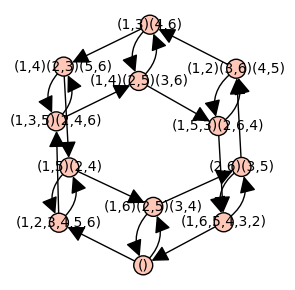

In [24]:
import matplotlib.pyplot as plt

#Here we supply the cayley graph from sage.
def plotcayleygraph(cay, axisbool: bool = False, figuresize: tuple[int, int] = (3, 3), vertexsize: int = 400, layoutstr: str = "circular"):

    """Plot a Sage Cayley (di)graph via matplotlib."""
    if not isinstance(vertexsize, int):
        raise TypeError(f"vertexsize must be int, got {type(vertexsize).__name__}")
    if not isinstance(layoutstr, str):
        raise TypeError(f"layoutstr must be str, got {type(layoutstr).__name__}")

    fig = plt.figure(figsize=figuresize)  # not plt.figure(figuresize)
    cay.plot(layout=layoutstr, vertex_size=vertexsize).matplotlib(figure=fig)
    plt.axis("on" if axisbool else "off")
    plt.tight_layout()
    plt.show()

plotcayleygraph(DihedralGroup(6).cayley_graph(), layoutstr='spring')
# Sage Graphics often only prints repr in some Jupyter UIs; draw via matplotlib.

In [25]:
# Which orders to include. Keep ≤ 64 for reasonable graph sizes.
ORDERS = list(range(2, 33))          # orders 2..32 — adjust as needed
# How many generating sets to sample per group.
# Set to 1 for the canonical minimal generating set only.
# Set to 3+ for generating-set-augmented diversity.
SAMPLES_PER_GROUP = 2
# Maximum generating set size to try.
MAX_GEN_SET_SIZE = 4

In [26]:
def group_id_str(G):
    """Return a canonical string id for a group G."""
    try:
        n = gap.Order(G)
        idx = gap.SmallGroupsInformation(n)   # just to verify GAP database exists
        gid = list(gap.IdGroup(G))
        return "SmallGroup({},{})".format(gid[0], gid[1])
    except Exception:
        return "{}".format(G.structure_description())


In [27]:
def perm_to_str(p):
    """Stable string representation of a permutation."""
    return str(p.cycle_tuples())
    
def canonical_generator_tuple(gens):
    """
    Canonicalized tuple of generator strings, used to avoid duplicates
    coming from reordering the same generating set. There is probably a better method here
    """
    return tuple(sorted(perm_to_str(s) for s in gens))

#The group will be abelian iff the generators commute. 
def generators_commute(gens):
    """Quick test: if generators commute pairwise, generated group is abelian."""
    for a, b in itertools.combinations(gens, 2):
        if a * b != b * a:
            return False
    return True


In [28]:

def find_generating_sets(G, n_samples=1, max_size=MAX_GEN_SET_SIZE):
    """
    Return up to n_samples distinct generating sets for G.
    Strategy:
      1. Always include the canonical GAP-minimal generating set.
      2. Sample additional ones by random selection from G.
    """
    elems = list(G)
    identity = G.identity()
    results = []

    # --- Canonical minimal generating set via GAP ---
    try:
        gap_gens = list(G.gap().MinimalGeneratingSet())
        canonical = [G(g) for g in gap_gens]
        if canonical and G.is_generated_by(canonical):
            results.append(canonical)
    except Exception:
        pass

    # --- Random samples ---
    import random
    random.seed(42)
    attempts = 0
    while len(results) < n_samples and attempts < 200:
        attempts += 1
        size = random.randint(1, min(max_size, len(elems) - 1))
        candidates = [e for e in elems if e != identity]
        if len(candidates) < size:
            break
        sample = random.sample(candidates, size)
        if G.is_generated_by(sample):
            # Deduplicate by frozenset of element orders and positions
            key = frozenset(s.__repr__() for s in sample)
            if not any(frozenset(r.__repr__() for r in existing) == key
                       for existing in results):
                results.append(sample)

    if not results:
        # Fallback: use all non-identity elements
        non_id = [e for e in elems if e != identity]
        if G.is_generated_by(non_id):
            results.append(non_id)

    return results[:n_samples]

In [29]:
find_generating_sets(DihedralGroup(6))

AttributeError: 'DihedralGroup_with_category' object has no attribute 'is_generated_by'